# RoBERTa-base Sentiment Analysis - Amazon Reviews

Eksperyment z pelna RoBERTa do porownania z poprzednimi modelami:
- **SVM + TF-IDF**
- **BiLSTM + GloVe**
- **RoBERTa / DistilRoBERTa**

Notebook jest ustawiony tak, zeby byl mozliwy do uruchomienia na komputerze z ok. 16 GB RAM:
- uzywa `roberta-base`, czyli pelniejszego i ciezszego wariantu niz `distilroberta-base`,
- tokenizuje teksty w batchach w `collate_fn`, a nie zapisuje calego zakodowanego zbioru w RAM,
- uzywa malego batch size i gradient accumulation,
- ogranicza dlugosc sekwencji do 192 tokenow,
- ma early stopping na zbiorze walidacyjnym,
- **zapisuje checkpoint po kazdej epoce** (epoch checkpoint) + najlepszy model (best checkpoint),
- **wspiera wznowienie treningu** od dowolnej epoki przez ustawienie `RESUME_FROM_EPOCH`.

> Finalny eksperyment uruchomiono w Google Colab (GPU T4). Plik `data/processed_reviews.csv` został wgrany do Colaba jako ZIP i rozpakowany do `sample_data/`.


In [4]:
!unzip -o sample_data/processed_reviews.csv.zip -d sample_data

Archive:  sample_data/processed_reviews.csv.zip
  inflating: sample_data/processed_reviews.csv  
  inflating: sample_data/__MACOSX/._processed_reviews.csv  


## 1. Importy i ustawienia

In [8]:
import os
import re
import time
import math
import copy
import random
import gc
import json
from pathlib import Path
from dataclasses import dataclass

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup,
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score

from tqdm.auto import tqdm
import seaborn as sns
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')

# Zostawiamy troche oddechu systemowi przy treningu na CPU.
if DEVICE.type == 'cpu':
    torch.set_num_threads(max(1, (os.cpu_count() or 2) - 2))

print(f'Urzadzenie: {DEVICE}')
print(f'PyTorch: {torch.__version__}')


Urzadzenie: cuda
PyTorch: 2.10.0+cu128


## 2. Konfiguracja eksperymentu

Ustawienia dla mocniejszego, ale ciezszego eksperymentu `roberta-base`. Najwazniejsze pokretla:
- `MODEL_NAME`: `roberta-base` daje mocniejszy, ale znacznie ciezszy eksperyment niz `distilroberta-base`.
- `MAX_LENGTH`: 192 pozwala zachowac wiecej kontekstu recenzji, ale zwieksza czas i zuzycie pamieci.
- `LIMIT_TRAIN_PER_CLASS`: ustaw np. `3000`, jesli chcesz szybki test techniczny.
- `RESUME_FROM_EPOCH`: ustaw np. `2`, zeby wznowic trening od epoki 2 (wczyta checkpoint z epoki 1).
  Ustaw `None` lub `0`, zeby startowac od poczatku.
- `FREEZE_LAYERS`: ile poczatkowych warstw encodera zamrozic. `0` = brak zamrozenia (pelny fine-tuning).
  Na CPU warto sprobowac `4` — przyspiesza trening kosztem niewielkiego spadku jakosci.

In [ ]:
MODEL_NAME = 'roberta-base'

MAX_LENGTH = 192
NUM_CLASSES = 3
TARGET_NAMES = ['Negative (0)', 'Neutral (1)', 'Positive (2)']

# None = pelny zbior treningowy. Liczba = szybki test, np. 3000 probek na klase.
LIMIT_TRAIN_PER_CLASS = None

# ── Wznowienie treningu ────────────────────────────────────────────────────────
# Ustaw numer epoki, od KTOREJ chcesz kontynuowac (wczyta checkpoint z epoki RESUME_FROM_EPOCH-1).
# Przyklad: RESUME_FROM_EPOCH = 2  ->  wczyta epoch_01 i zacznie epoke 2.
# Ustaw None lub 0, zeby startowac od zera.
RESUME_FROM_EPOCH = None

# ── Zamrazanie warstw (przyspiesza CPU) ───────────────────────────────────────
# 0 = pelny fine-tuning; w razie braku pamieci na Colabie mozna sprobowac 4 lub 6
FREEZE_LAYERS = 0

if DEVICE.type == 'cuda':
    # roberta-base + MAX_LENGTH=192 jest ciezsza niz DistilRoBERTa.
    # Batch 8 + accumulation 4 zachowuje efektywny batch 32 i zwykle miesci sie na Colab T4.
    TRAIN_BATCH_SIZE = 8
    EVAL_BATCH_SIZE = 16
    GRADIENT_ACCUMULATION_STEPS = 4
    USE_AMP = True
elif DEVICE.type == 'mps':
    # roberta-base + MAX_LENGTH=192 najpewniej bedzie za ciezka na MPS; to tylko awaryjny wariant.
    TRAIN_BATCH_SIZE = 1
    EVAL_BATCH_SIZE = 2
    GRADIENT_ACCUMULATION_STEPS = 32
    USE_AMP = False
else:  # CPU
    TRAIN_BATCH_SIZE = 4
    EVAL_BATCH_SIZE = 8
    GRADIENT_ACCUMULATION_STEPS = 8
    USE_AMP = False

# W notebooku na macOS multiprocessing DataLoadera potrafi sie zawieszac
# albo byc wolniejszy niz tokenizacja w glownym procesie.
TRAIN_NUM_WORKERS = 0

LEARNING_RATE = 1e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.06   # 6% krokow jako warmup (standard dla transformerow)
MAX_EPOCHS = 4
PATIENCE = 2
MAX_GRAD_NORM = 1.0

# Pelne checkpointy epok zawieraja optimizer i moga zajmowac ~1 GB na epoke.
# Przy malym miejscu na dysku bezpieczniej zostawic tylko best checkpoint.
SAVE_EPOCH_CHECKPOINTS = False

LR_TAG = f'{LEARNING_RATE:.0e}'.replace('-', 'm')
RUN_NAME = f"{MODEL_NAME.replace('/', '_')}_len{MAX_LENGTH}_lr{LR_TAG}"
CHECKPOINT_DIR      = Path('models') / f'{RUN_NAME}_best'    # najlepszy model
EPOCH_CHECKPOINT_DIR = Path('models') / f'{RUN_NAME}_epochs'  # checkpoint po kazdej epoce

print('Konfiguracja:')
print(f'  MODEL_NAME:                {MODEL_NAME}')
print(f'  MAX_LENGTH:                {MAX_LENGTH}')
print(f'  TRAIN_BATCH_SIZE:          {TRAIN_BATCH_SIZE}')
print(f'  EVAL_BATCH_SIZE:           {EVAL_BATCH_SIZE}')
print(f'  GRADIENT_ACCUMULATION_STEPS: {GRADIENT_ACCUMULATION_STEPS}')
print(f'  Efektywny batch size:      {TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS}')
print(f'  FREEZE_LAYERS:             {FREEZE_LAYERS}')
print(f'  WARMUP_RATIO:              {WARMUP_RATIO}')
print(f'  PATIENCE:                  {PATIENCE}')
print(f'  RESUME_FROM_EPOCH:         {RESUME_FROM_EPOCH}')
print(f'  CHECKPOINT_DIR:            {CHECKPOINT_DIR}')
print(f'  EPOCH_CHECKPOINT_DIR:      {EPOCH_CHECKPOINT_DIR}')


Konfiguracja:
  MODEL_NAME:                roberta-base
  MAX_LENGTH:                192
  TRAIN_BATCH_SIZE:          8
  EVAL_BATCH_SIZE:           16
  GRADIENT_ACCUMULATION_STEPS: 4
  Efektywny batch size:      32
  FREEZE_LAYERS:             0
  WARMUP_RATIO:              0.06
  PATIENCE:                  2
  RESUME_FROM_EPOCH:         None
  CHECKPOINT_DIR:            models/roberta-base_len192_lr1em05_best
  EPOCH_CHECKPOINT_DIR:      models/roberta-base_len192_lr1em05_epochs


## 3. Wczytanie i lekkie czyszczenie danych

In [10]:
def clean_text(text):
    text = str(text)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

DATA_PATH = 'sample_data/processed_reviews.csv'
df = pd.read_csv(DATA_PATH)
df['clean_text'] = df['full_text'].map(clean_text)
df['label'] = df['label'].astype(int)

print(f'Liczba probek: {len(df)}')
print(f'Kolumny: {df.columns.tolist()}')
print('\nRozklad klas:')
print(df['label'].value_counts().sort_index())

expected_counts = {0: 29837, 1: 29837, 2: 29837}
actual_counts = df['label'].value_counts().sort_index().to_dict()
if len(df) != 89511 or actual_counts != expected_counts:
    raise ValueError(
        f'Niepelny albo inny dataset: len={len(df)}, counts={actual_counts}. '
        'Sprawdz upload ZIP/CSV w Colabie przed treningiem.'
    )

df[['clean_text', 'score', 'sentiment', 'label']].head(3)

Liczba probek: 89511
Kolumny: ['id', 'full_text', 'score', 'sentiment', 'label', 'clean_text']

Rozklad klas:
label
0    29837
1    29837
2    29837
Name: count, dtype: int64


,clean_text,score,sentiment,label
0,It's not equal amounts of each flavor... Just ...,3,0,1
1,Not A Gingerbread Man These do taste very good...,4,1,2
2,"great taste great taste, good price... Always ...",5,1,2


## 4. Podzial train / validation / test

Uzywamy takiego samego schematu jak w notebooku BiLSTM:
- 70% train,
- 10% validation,
- 20% test.

Test zostaje odlozony do finalnej ewaluacji.

In [12]:
X = df['clean_text']
y = df['label']

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.125, random_state=SEED, stratify=y_temp
)

if LIMIT_TRAIN_PER_CLASS is not None:
    train_df = pd.DataFrame({'text': X_train, 'label': y_train})
    train_df = (
        train_df.groupby('label', group_keys=False)
        .apply(lambda g: g.sample(n=min(LIMIT_TRAIN_PER_CLASS, len(g)), random_state=SEED))
        .sample(frac=1, random_state=SEED)
        .reset_index(drop=True)
    )
    X_train = train_df['text']
    y_train = train_df['label']

print(f'Train:      {len(X_train):>6} probek ({len(X_train)/len(X)*100:.1f}%)')
print(f'Validation: {len(X_val):>6} probek ({len(X_val)/len(X)*100:.1f}%)')
print(f'Test:       {len(X_test):>6} probek ({len(X_test)/len(X)*100:.1f}%)')

print('\nRozklad klas w Train:')
print(y_train.value_counts().sort_index())
print('\nRozklad klas w Validation:')
print(y_val.value_counts().sort_index())
print('\nRozklad klas w Test:')
print(y_test.value_counts().sort_index())


Train:       62657 probek (70.0%)
Validation:   8951 probek (10.0%)
Test:        17903 probek (20.0%)

Rozklad klas w Train:
label
0    20886
1    20885
2    20886
Name: count, dtype: int64

Rozklad klas w Validation:
label
0    2984
1    2984
2    2983
Name: count, dtype: int64

Rozklad klas w Test:
label
0    5967
1    5968
2    5968
Name: count, dtype: int64


## 5. Dataset i DataLoader

Tokenizacja dzieje sie dynamicznie dla kazdego batcha w train_loader.
Natomiast zbiory val i test sa **pre-tokenizowane raz** — nie zmieniaja sie miedzy epokami,
wiec nie ma sensu tokenizowac ich za kazdym razem od nowa.

In [13]:
class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = list(texts)
        self.labels = list(labels.astype(int))

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.texts[idx], self.labels[idx]


class PreTokenizedDataset(Dataset):
    """Zbior danych z tokenizacja wykonana raz przy inicjalizacji.
    Uzyj dla val i test — nie zmieniaja sie miedzy epokami."""
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = list(labels.astype(int))

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item


tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

@dataclass
class RobertaCollator:
    tokenizer: object
    max_length: int

    def __call__(self, batch):
        texts, labels = zip(*batch)
        encoded = self.tokenizer(
            list(texts),
            padding=True,
            truncation=True,
            max_length=self.max_length,
            return_tensors='pt'
        )
        encoded['labels'] = torch.tensor(labels, dtype=torch.long)
        return encoded


collator = RobertaCollator(tokenizer=tokenizer, max_length=MAX_LENGTH)

# Train: lazy tokenizacja (oszczedza RAM)
train_dataset = TextDataset(X_train, y_train)
generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    generator=generator,
    collate_fn=collator,
    num_workers=TRAIN_NUM_WORKERS,
    persistent_workers=(TRAIN_NUM_WORKERS > 0),
    pin_memory=(DEVICE.type == 'cuda')
)

# Val i test: tokenizacja raz na poczatku
print('Tokenizuje val i test (jednorazowo)...')
val_encodings = tokenizer(
    list(X_val), truncation=True, padding=True,
    max_length=MAX_LENGTH, return_tensors='pt'
)
test_encodings = tokenizer(
    list(X_test), truncation=True, padding=True,
    max_length=MAX_LENGTH, return_tensors='pt'
)

val_dataset  = PreTokenizedDataset(val_encodings,  y_val)
test_dataset = PreTokenizedDataset(test_encodings, y_test)

val_loader = DataLoader(
    val_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=(DEVICE.type == 'cuda')
)
test_loader = DataLoader(
    test_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=(DEVICE.type == 'cuda')
)

print(f'Train batche:      {len(train_loader)}')
print(f'Validation batche: {len(val_loader)}')
print(f'Test batche:       {len(test_loader)}')
print('Tokenizacja val/test gotowa.')


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenizuje val i test (jednorazowo)...
Train batche:      7833
Validation batche: 560
Test batche:       1119
Tokenizacja val/test gotowa.


## 6. Model RoBERTa

In [14]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_CLASSES,
    id2label={0: 'negative', 1: 'neutral', 2: 'positive'},
    label2id={'negative': 0, 'neutral': 1, 'positive': 2}
)
model.to(DEVICE)

if hasattr(model.config, 'use_cache'):
    model.config.use_cache = False

# ── Opcjonalne zamrazanie poczatkowych warstw (przyspiesza CPU) ───────────────
if FREEZE_LAYERS > 0:
    # Obsluguje distilroberta (transformer.layer) i roberta (encoder.layer)
    layers = None
    if hasattr(model, 'distilroberta'):
        layers = model.distilroberta.transformer.layer
    elif hasattr(model, 'roberta'):
        layers = model.roberta.encoder.layer

    if layers is not None:
        n_to_freeze = min(FREEZE_LAYERS, len(layers))
        for layer in layers[:n_to_freeze]:
            for param in layer.parameters():
                param.requires_grad = False
        print(f'Zamroznięto {n_to_freeze}/{len(layers)} warstw encodera.')
    else:
        print('Nie rozpoznano architektury do zamrazania — pomijam FREEZE_LAYERS.')

optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model.__class__.__name__)
print(f'Laczna liczba parametrow:  {total_params:,}')
print(f'Trenowalne parametry:      {trainable_params:,}')
print(f'Zamrozone parametry:       {total_params - trainable_params:,}')


model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
classifier.out_proj.weight      | MISSING    | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.dense.bias           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


RobertaForSequenceClassification
Laczna liczba parametrow:  124,647,939
Trenowalne parametry:      124,647,939
Zamrozone parametry:       0


/tmp/ipykernel_1981/58208579.py:31: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


## 7. Funkcje treningu i ewaluacji

In [15]:
def move_batch_to_device(batch, device):
    return {k: v.to(device) for k, v in batch.items()}


def train_epoch(model, loader, optimizer, scheduler):
    model.train()
    total_loss = 0.0
    all_preds, all_labels = [], []
    optimizer.zero_grad(set_to_none=True)

    progress = tqdm(loader, desc='Train', leave=True)
    for step, batch in enumerate(progress, start=1):
        batch = move_batch_to_device(batch, DEVICE)
        labels = batch['labels']

        with torch.amp.autocast(device_type='cuda', enabled=USE_AMP):
            outputs = model(**batch)
            loss = outputs.loss / GRADIENT_ACCUMULATION_STEPS

        scaler.scale(loss).backward()

        if step % GRADIENT_ACCUMULATION_STEPS == 0 or step == len(loader):
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()  # LR scheduler krok po kazdym optimizer.step()
            optimizer.zero_grad(set_to_none=True)

        total_loss += loss.item() * GRADIENT_ACCUMULATION_STEPS
        if step % 50 == 0 or step == len(loader):
            progress.set_postfix(loss=f'{total_loss / step:.4f}')
        preds = outputs.logits.argmax(dim=1).detach().cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.detach().cpu().numpy())

        del batch, outputs, loss

    avg_loss = total_loss / len(loader)
    f1 = f1_score(all_labels, all_preds, average='macro')
    return avg_loss, f1


@torch.inference_mode()  # szybsze niz @torch.no_grad() — wylacza caly autograd
def evaluate(model, loader, desc='Eval'):
    model.eval()
    total_loss = 0.0
    all_preds, all_labels = [], []

    progress = tqdm(loader, desc=desc, leave=True)
    for batch in progress:
        batch = move_batch_to_device(batch, DEVICE)
        labels = batch['labels']
        outputs = model(**batch)
        loss = outputs.loss

        total_loss += loss.item()
        preds = outputs.logits.argmax(dim=1).detach().cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.detach().cpu().numpy())

        del batch, outputs, loss

    avg_loss = total_loss / len(loader)
    f1 = f1_score(all_labels, all_preds, average='macro')
    return avg_loss, f1, all_preds, all_labels


print('Funkcje treningowe zdefiniowane.')


Funkcje treningowe zdefiniowane.


## 8. Helpery do zapisu i wczytywania checkpointow

Dwa rodzaje checkpointow:
- **epoch checkpoint** (`models/roberta_..._epochs/epoch_NN/`) — pelny stan po kazdej epoce
  (model + optimizer + scheduler + history). Pozwala wznowic trening dokladnie od tego miejsca.
- **best checkpoint** (`models/roberta_..._best/`) — tylko wagi najlepszego modelu
  (format kompatybilny z `from_pretrained`). Do inference i porowania wynikow.

In [16]:
def save_epoch_checkpoint(epoch, model, optimizer, scheduler, history,
                           best_val_f1, best_epoch, epochs_no_improve):
    """Zapisuje pelny stan treningu po epoce — umozliwia wznowienie."""
    if not SAVE_EPOCH_CHECKPOINTS:
        print('  [Checkpoint] Pominieto pelny checkpoint epoki (SAVE_EPOCH_CHECKPOINTS=False)')
        return

    ckpt_path = EPOCH_CHECKPOINT_DIR / f'epoch_{epoch:02d}'
    ckpt_path.mkdir(parents=True, exist_ok=True)

    # Wagi modelu (format HuggingFace — mozna tez ladowac przez from_pretrained)
    model.save_pretrained(ckpt_path)
    tokenizer.save_pretrained(ckpt_path)

    # Stan optymalizatora, schedulera i historii treningu
    torch.save({
        'epoch': epoch,
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'scaler_state_dict': scaler.state_dict(),
        'history': history,
        'best_val_f1': best_val_f1,
        'best_epoch': best_epoch,
        'epochs_no_improve': epochs_no_improve,
    }, ckpt_path / 'training_state.pt')

    print(f'  [Checkpoint] Zapisano stan epoki {epoch} -> {ckpt_path}')


def load_epoch_checkpoint(resume_epoch, model, optimizer, scheduler):
    """Wczytuje stan treningu z checkpointu epoki `resume_epoch - 1`.
    Zwraca (start_epoch, history, best_val_f1, best_epoch, epochs_no_improve)."""
    load_epoch = resume_epoch - 1
    ckpt_path = EPOCH_CHECKPOINT_DIR / f'epoch_{load_epoch:02d}'

    if not ckpt_path.exists():
        raise FileNotFoundError(
            f'Brak checkpointu dla epoki {load_epoch}: {ckpt_path}\n'
            f'Dostepne checkpointy: {sorted(EPOCH_CHECKPOINT_DIR.glob("epoch_*")) if EPOCH_CHECKPOINT_DIR.exists() else "brak katalogu"}'
        )

    # Wagi modelu
    loaded_model = AutoModelForSequenceClassification.from_pretrained(ckpt_path)
    model.load_state_dict(loaded_model.state_dict())
    model.to(DEVICE)
    del loaded_model

    # Stan optymalizatora, schedulera, historii
    state = torch.load(ckpt_path / 'training_state.pt', map_location=DEVICE)
    optimizer.load_state_dict(state['optimizer_state_dict'])
    scheduler.load_state_dict(state['scheduler_state_dict'])
    scaler.load_state_dict(state['scaler_state_dict'])

    print(f'Wczytano checkpoint z epoki {load_epoch} ({ckpt_path})')
    print(f'Kontynuacja od epoki {resume_epoch}')
    print(f'  Dotychczasowe best_val_f1: {state["best_val_f1"]:.4f} (epoka {state["best_epoch"]})')

    return (
        resume_epoch,
        state['history'],
        state['best_val_f1'],
        state['best_epoch'],
        state['epochs_no_improve'],
    )


def save_best_checkpoint(epoch, model, val_f1, val_loss, train_loss, train_f1, epoch_time):
    """Zapisuje najlepszy model w formacie from_pretrained (tylko wagi, bez optimizera)."""
    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(CHECKPOINT_DIR)
    tokenizer.save_pretrained(CHECKPOINT_DIR)
    info = {
        'model_name': MODEL_NAME,
        'best_epoch': epoch,
        'best_val_f1': float(val_f1),
        'val_loss': float(val_loss),
        'train_loss': float(train_loss),
        'train_f1': float(train_f1),
        'max_length': MAX_LENGTH,
        'train_batch_size': TRAIN_BATCH_SIZE,
        'eval_batch_size': EVAL_BATCH_SIZE,
        'gradient_accumulation_steps': GRADIENT_ACCUMULATION_STEPS,
        'learning_rate': LEARNING_RATE,
        'weight_decay': WEIGHT_DECAY,
        'warmup_ratio': WARMUP_RATIO,
        'freeze_layers': FREEZE_LAYERS,
        'limit_train_per_class': LIMIT_TRAIN_PER_CLASS,
        'epoch_time_seconds': float(epoch_time),
    }
    with open(CHECKPOINT_DIR / 'training_info.json', 'w', encoding='utf-8') as f:
        json.dump(info, f, indent=2, ensure_ascii=False)
    print(f'  [Best] Zapisano najlepszy checkpoint: {CHECKPOINT_DIR} (F1={val_f1:.4f})')


print('Helpery checkpointow zdefiniowane.')


Helpery checkpointow zdefiniowane.


## 9. Trening z early stopping, LR schedulerem i checkpointami

- **LR scheduler**: linear warmup (6% krokow) + linear decay do 0. Standard dla transformerow.
- **Epoch checkpoint**: po kazdej epoce zapisuje pelny stan (model + optimizer + scheduler + historia).
- **Best checkpoint**: zapisuje najlepszy model (wg val F1-macro) w formacie `from_pretrained`.
- **Wznowienie**: jesli `RESUME_FROM_EPOCH` jest ustawione, wczytuje stan z poprzedniej epoki i kontynuuje.

In [17]:
# ── Scheduler — musi byc stworzony przed ewentualnym wczytaniem checkpointu ──
num_update_steps_per_epoch = max(1, math.ceil(len(train_loader) / GRADIENT_ACCUMULATION_STEPS))
num_training_steps = num_update_steps_per_epoch * MAX_EPOCHS
num_warmup_steps   = int(WARMUP_RATIO * num_training_steps)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=num_warmup_steps,
    num_training_steps=num_training_steps,
)

print(f'Scheduler: warmup={num_warmup_steps} krokow, lacznie={num_training_steps} krokow')

# ── Inicjalizacja stanu treningu ──────────────────────────────────────────────
history          = {'train_loss': [], 'val_loss': [], 'train_f1': [], 'val_f1': []}
epochs_ran       = 0
best_val_f1      = -1.0
best_model_wts   = None
best_epoch       = 0
epochs_no_improve = 0
start_epoch      = 1

# ── Wznowienie treningu (opcjonalne) ──────────────────────────────────────────
if RESUME_FROM_EPOCH and RESUME_FROM_EPOCH > 1:
    start_epoch, history, best_val_f1, best_epoch, epochs_no_improve = \
        load_epoch_checkpoint(RESUME_FROM_EPOCH, model, optimizer, scheduler)

EPOCH_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print(f'\nTrening {MODEL_NAME} | epoki {start_epoch}–{MAX_EPOCHS} | patience={PATIENCE}')
print('=' * 75)

start = time.time()
for epoch in range(start_epoch, MAX_EPOCHS + 1):
    t0 = time.time()

    print(f'\nStart epoki {epoch}: trening...', flush=True)
    train_loss, train_f1 = train_epoch(model, train_loader, optimizer, scheduler)
    print(f'Epoka {epoch}: walidacja...', flush=True)
    val_loss, val_f1, _, _ = evaluate(model, val_loader, desc='Validation')

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_f1'].append(train_f1)
    history['val_f1'].append(val_f1)
    epochs_ran = len(history['train_loss'])

    epoch_time = time.time() - t0
    print(f'Epoka {epoch:>2}/{MAX_EPOCHS} | '
          f'Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f} | '
          f'Train F1: {train_f1:.4f} | Val F1: {val_f1:.4f} | '
          f'{epoch_time:.0f}s')

    should_stop = False

    # ── Best checkpoint (tylko jesli poprawa) ─────────────────────────────────
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch  = epoch
        best_model_wts = copy.deepcopy({k: v.detach().cpu() for k, v in model.state_dict().items()})
        epochs_no_improve = 0
        save_best_checkpoint(epoch, model, val_f1, val_loss, train_loss, train_f1, epoch_time)
    else:
        epochs_no_improve += 1
        print(f'  Brak poprawy ({epochs_no_improve}/{PATIENCE})')
        if epochs_no_improve >= PATIENCE:
            print(f'\nEarly stopping po epoce {epoch} (brak poprawy F1 przez {PATIENCE} epoki)')
            should_stop = True

    # ── Epoch checkpoint (zawsze, juz po aktualizacji best/early stopping) ─────
    save_epoch_checkpoint(
        epoch, model, optimizer, scheduler, history,
        best_val_f1, best_epoch, epochs_no_improve
    )

    if should_stop:
        break

    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()

# Przywroc najlepsze wagi do dalszej ewaluacji
if best_model_wts is not None:
    model.load_state_dict(best_model_wts)
    model.to(DEVICE)

epochs_ran = len(history['train_loss'])
print(f'\nCalkowity czas treningu: {time.time() - start:.0f}s')
print(f'Najlepsza epoka: {best_epoch} (val F1: {best_val_f1:.4f})')
print(f'Best checkpoint: {CHECKPOINT_DIR}')
print(f'Epoch checkpointy: {EPOCH_CHECKPOINT_DIR}')


Scheduler: warmup=470 krokow, lacznie=7836 krokow

Trening roberta-base | epoki 1–4 | patience=2

Start epoki 1: trening...


Train:   0%|          | 0/7833 [00:00<?, ?it/s]

Epoka 1: walidacja...


Validation:   0%|          | 0/560 [00:00<?, ?it/s]

Epoka  1/4 | Train loss: 0.5406 | Val loss: 0.4532 | Train F1: 0.7567 | Val F1: 0.8091 | 751s


...

  [Best] Zapisano najlepszy checkpoint: models/roberta-base_len192_lr1em05_best (F1=0.8312)
  [Checkpoint] Pominieto pelny checkpoint epoki (SAVE_EPOCH_CHECKPOINTS=False)

Start epoki 4: trening...


Train:   0%|          | 0/7833 [00:00<?, ?it/s]

Epoka 4: walidacja...


Validation:   0%|          | 0/560 [00:00<?, ?it/s]

Epoka  4/4 | Train loss: 0.3049 | Val loss: 0.4439 | Train F1: 0.8806 | Val F1: 0.8305 | 754s
  Brak poprawy (1/2)
  [Checkpoint] Pominieto pelny checkpoint epoki (SAVE_EPOCH_CHECKPOINTS=False)

Calkowity czas treningu: 3060s
Najlepsza epoka: 3 (val F1: 0.8312)
Best checkpoint: models/roberta-base_len192_lr1em05_best
Epoch checkpointy: models/roberta-base_len192_lr1em05_epochs


## 10. Krzywe uczenia

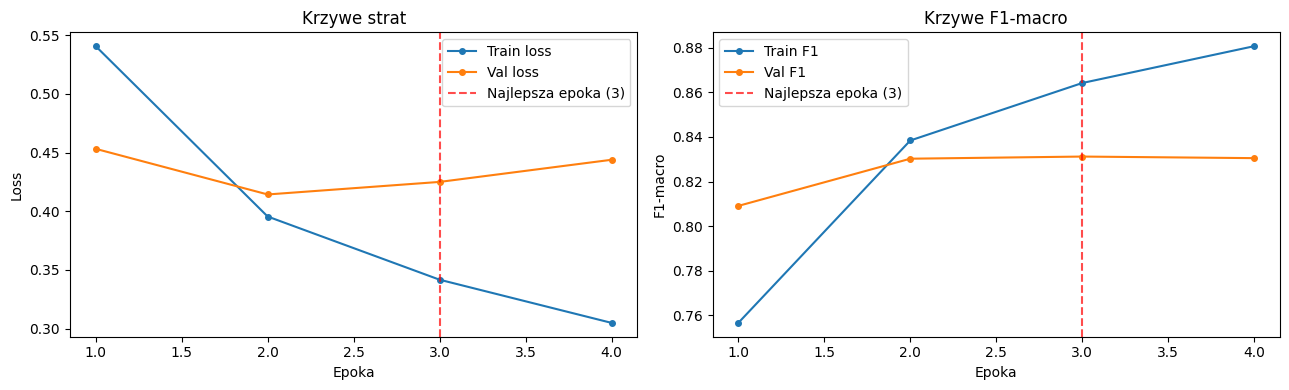

Gap train-val F1 w najlepszej epoce: +0.0329 <-- ok


In [18]:
epochs_ran = len(history['train_loss'])
ep = range(1, epochs_ran + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

ax1.plot(ep, history['train_loss'], label='Train loss', marker='o', markersize=4)
ax1.plot(ep, history['val_loss'],   label='Val loss',   marker='o', markersize=4)
if best_epoch > 0:
    ax1.axvline(best_epoch, color='red', linestyle='--', alpha=0.7, label=f'Najlepsza epoka ({best_epoch})')
ax1.set_xlabel('Epoka'); ax1.set_ylabel('Loss'); ax1.set_title('Krzywe strat'); ax1.legend()

ax2.plot(ep, history['train_f1'], label='Train F1', marker='o', markersize=4)
ax2.plot(ep, history['val_f1'],   label='Val F1',   marker='o', markersize=4)
if best_epoch > 0:
    ax2.axvline(best_epoch, color='red', linestyle='--', alpha=0.7, label=f'Najlepsza epoka ({best_epoch})')
ax2.set_xlabel('Epoka'); ax2.set_ylabel('F1-macro'); ax2.set_title('Krzywe F1-macro'); ax2.legend()

plt.tight_layout()
plt.show()

if best_epoch > 0:
    gap = history['train_f1'][best_epoch - 1] - history['val_f1'][best_epoch - 1]
    print(f'Gap train-val F1 w najlepszej epoce: {gap:+.4f}',
          '<-- ok' if gap < 0.05 else '<-- uwaga, mozliwe przeuczenie')


## 11. Wyniki walidacyjne

Validation final:   0%|          | 0/560 [00:00<?, ?it/s]

WYNIKI NA ZBIORZE WALIDACYJNYM
F1-macro (validation): 0.8312

              precision    recall  f1-score   support

Negative (0)       0.82      0.82      0.82      2984
 Neutral (1)       0.76      0.75      0.76      2984
Positive (2)       0.91      0.92      0.92      2983

    accuracy                           0.83      8951
   macro avg       0.83      0.83      0.83      8951
weighted avg       0.83      0.83      0.83      8951



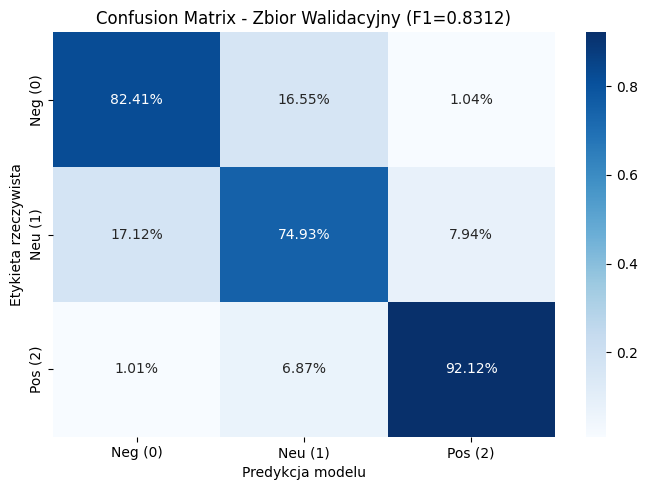

In [19]:
_, val_f1_final, val_preds, val_labels = evaluate(model, val_loader, desc='Validation final')

print('=' * 55)
print('WYNIKI NA ZBIORZE WALIDACYJNYM')
print('=' * 55)
print(f'F1-macro (validation): {val_f1_final:.4f}')
print()
print(classification_report(val_labels, val_preds, target_names=TARGET_NAMES))

cm_val = confusion_matrix(val_labels, val_preds)
cm_val_pct = cm_val.astype(float) / cm_val.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(7, 5))
sns.heatmap(cm_val_pct, annot=True, fmt='.2%', cmap='Blues',
            xticklabels=['Neg (0)', 'Neu (1)', 'Pos (2)'],
            yticklabels=['Neg (0)', 'Neu (1)', 'Pos (2)'])
plt.ylabel('Etykieta rzeczywista')
plt.xlabel('Predykcja modelu')
plt.title(f'Confusion Matrix - Zbior Walidacyjny (F1={val_f1_final:.4f})')
plt.tight_layout()
plt.show()


## 12. Finalna ewaluacja na zbiorze testowym

Test:   0%|          | 0/1119 [00:00<?, ?it/s]

FINALNE WYNIKI NA ZBIORZE TESTOWYM
Val F1-macro  (najlepsza epoka): 0.8312
Test F1-macro (FINALNA):         0.8331

              precision    recall  f1-score   support

Negative (0)       0.83      0.82      0.82      5967
 Neutral (1)       0.76      0.76      0.76      5968
Positive (2)       0.91      0.92      0.91      5968

    accuracy                           0.83     17903
   macro avg       0.83      0.83      0.83     17903
weighted avg       0.83      0.83      0.83     17903



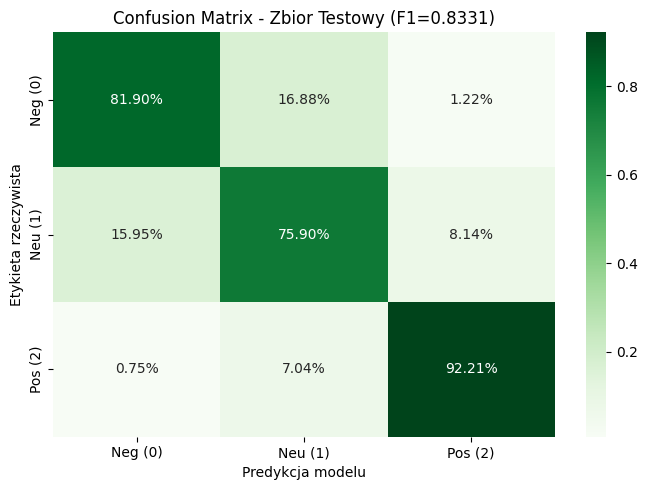

In [20]:
_, test_f1, test_preds, test_labels = evaluate(model, test_loader, desc='Test')

print('=' * 55)
print('FINALNE WYNIKI NA ZBIORZE TESTOWYM')
print('=' * 55)
print(f'Val F1-macro  (najlepsza epoka): {val_f1_final:.4f}')
print(f'Test F1-macro (FINALNA):         {test_f1:.4f}')
print()
print(classification_report(test_labels, test_preds, target_names=TARGET_NAMES))

cm_test = confusion_matrix(test_labels, test_preds)
cm_test_pct = cm_test.astype(float) / cm_test.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(7, 5))
sns.heatmap(cm_test_pct, annot=True, fmt='.2%', cmap='Greens',
            xticklabels=['Neg (0)', 'Neu (1)', 'Pos (2)'],
            yticklabels=['Neg (0)', 'Neu (1)', 'Pos (2)'])
plt.ylabel('Etykieta rzeczywista')
plt.xlabel('Predykcja modelu')
plt.title(f'Confusion Matrix - Zbior Testowy (F1={test_f1:.4f})')
plt.tight_layout()
plt.show()


## 13. Analiza błędów

Sprawdzamy, jakie klasy model myli najczęściej, ze szczególnym uwzględnieniem klasy neutralnej.

In [21]:
LABEL_NAMES = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}

results_df = pd.DataFrame({
    'text':      list(X_test),
    'actual':    test_labels,
    'predicted': test_preds
})
results_df['actual_name'] = results_df['actual'].map(LABEL_NAMES)
results_df['predicted_name'] = results_df['predicted'].map(LABEL_NAMES)

errors = results_df[results_df['actual'] != results_df['predicted']].copy()
error_rate = len(errors) / len(results_df)
print(f'Blednych predykcji: {len(errors)} / {len(results_df)} ({error_rate:.1%})')

print('\nMacierz pomylek actual -> predicted (liczba przypadkow):')
error_matrix = pd.crosstab(
    errors['actual_name'],
    errors['predicted_name'],
    rownames=['actual'],
    colnames=['predicted'],
    dropna=False
).reindex(index=LABEL_NAMES.values(), columns=LABEL_NAMES.values(), fill_value=0)
display(error_matrix)

print('\nNajczestsze typy pomylek:')
mistake_counts = (
    errors.groupby(['actual_name', 'predicted_name'])
    .size()
    .reset_index(name='count')
    .sort_values('count', ascending=False)
)
display(mistake_counts)

neutral_errors = errors[(errors['actual'] == 1) | (errors['predicted'] == 1)]
print(f'\nPomylki zwiazane z klasa neutralna: {len(neutral_errors)} / {len(errors)} ({len(neutral_errors)/len(errors):.1%} wszystkich bledow)')

def show_examples(df, title, n=5, max_chars=280):
    print(f'\n{title}: {len(df)} przypadkow')
    for _, row in df.head(n).iterrows():
        text = str(row['text']).replace('\n', ' ')
        print(f"\n[actual={row['actual_name']} | pred={row['predicted_name']}]")
        print(f'  {text[:max_chars]}...')

show_examples(errors[(errors['actual'] == 1) & (errors['predicted'] == 0)], 'Neutral -> Negative')
show_examples(errors[(errors['actual'] == 1) & (errors['predicted'] == 2)], 'Neutral -> Positive')
show_examples(errors[(errors['actual'] == 0) & (errors['predicted'] == 1)], 'Negative -> Neutral')
show_examples(errors[(errors['actual'] == 2) & (errors['predicted'] == 1)], 'Positive -> Neutral')
show_examples(errors[(errors['actual'] == 0) & (errors['predicted'] == 2)], 'Skrajne pomylki: Negative -> Positive')
show_examples(errors[(errors['actual'] == 2) & (errors['predicted'] == 0)], 'Skrajne pomylki: Positive -> Negative')


Blednych predykcji: 2983 / 17903 (16.7%)

Macierz pomylek actual -> predicted (liczba przypadkow):


predicted,Negative,Neutral,Positive
actual,,,
Negative,0,1007,73
Neutral,952,0,486
Positive,45,420,0



Najczestsze typy pomylek:


,actual_name,predicted_name,count
0,Negative,Neutral,1007
2,Neutral,Negative,952
3,Neutral,Positive,486
5,Positive,Neutral,420
1,Negative,Positive,73
4,Positive,Negative,45



Pomylki zwiazane z klasa neutralna: 2865 / 2983 (96.0% wszystkich bledow)

Neutral -> Negative: 952 przypadkow

[actual=Neutral | pred=Negative]
  Really? You people are crazy. The amount of salt in this product is off the salt scale. Way, Way too much and I like salt. I was shaking the can in hope some would fall off....

[actual=Neutral | pred=Negative]
  Love 'em worms The original gummy worm. This last package, which I take to work to share was borderline stale. They were leathery and had molding debris stuck on bunches of them. I remember when your worms never had warts, these had lots and should have been rejected. I think I'm...

[actual=Neutral | pred=Negative]
  Too runny... My baby LOVES sweet potatoes. I can essentially mix any food into sweet potatoes and he will eat them; which in this case could be a good or bad thing depending on what I wanted to mix in there... it was horribly runny, like spooning formula into his mouth. Ick....

[actual=Neutral | pred=Negative]
  Not 

## 14. Porownanie z poprzednimi modelami

Wyniki SVM i BiLSTM pochodza z notebookow `svm_sentiment_final.ipynb` oraz `bilstm_glove_sentiment_final.ipynb`.

,model,test_f1_macro,delta_vs_svm,delta_vs_bilstm
0,SVM + TF-IDF,0.776100,0.000000,-0.008000
1,BiLSTM + GloVe,0.784100,0.008000,0.000000
2,roberta-base,0.833123,0.057023,0.049023


/tmp/ipykernel_1981/4232169279.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparison_df, x='model', y='test_f1_macro', palette=['steelblue', 'seagreen', 'indianred'])


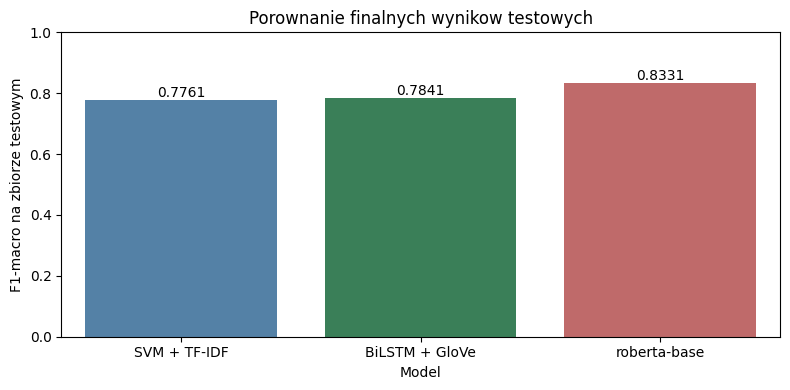

Roznica roberta-base - SVM:    +0.0570 F1-macro
Roznica roberta-base - BiLSTM: +0.0490 F1-macro


In [22]:
svm_test_f1    = 0.7761
bilstm_test_f1 = 0.7841

comparison_df = pd.DataFrame({
    'model':         ['SVM + TF-IDF', 'BiLSTM + GloVe', MODEL_NAME],
    'test_f1_macro': [svm_test_f1, bilstm_test_f1, test_f1]
})
comparison_df['delta_vs_svm']    = comparison_df['test_f1_macro'] - svm_test_f1
comparison_df['delta_vs_bilstm'] = comparison_df['test_f1_macro'] - bilstm_test_f1

display(comparison_df)

plt.figure(figsize=(8, 4))
sns.barplot(data=comparison_df, x='model', y='test_f1_macro', palette=['steelblue', 'seagreen', 'indianred'])
plt.ylim(0, 1)
plt.ylabel('F1-macro na zbiorze testowym')
plt.xlabel('Model')
plt.title('Porownanie finalnych wynikow testowych')
for i, score in enumerate(comparison_df['test_f1_macro']):
    plt.text(i, score + 0.01, f'{score:.4f}', ha='center')
plt.tight_layout()
plt.show()

print(f'Roznica {MODEL_NAME} - SVM:    {test_f1 - svm_test_f1:+.4f} F1-macro')
print(f'Roznica {MODEL_NAME} - BiLSTM: {test_f1 - bilstm_test_f1:+.4f} F1-macro')


## 15. Podsumowanie eksperymentu

In [23]:
print('=' * 55)
print('PODSUMOWANIE EKSPERYMENTU')
print('=' * 55)
print(f'\nModel:')
print(f'  Transformer:        {MODEL_NAME}')
print(f'  Max dlugosc seq.:   {MAX_LENGTH} tokenow')
print(f'  Liczba klas:        {NUM_CLASSES}')
print(f'  Zamrozone warstwy:  {FREEZE_LAYERS}')
print(f'\nPodzial danych:')
print(f'  Train:              {len(X_train):>6} probek')
print(f'  Validation:         {len(X_val):>6} probek')
print(f'  Test:               {len(X_test):>6} probek')
print(f'\nTrening:')
print(f'  Batch size:         {TRAIN_BATCH_SIZE}')
print(f'  Gradient accum.:    {GRADIENT_ACCUMULATION_STEPS}')
print(f'  Efektywny batch:    {TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS}')
print(f'  Learning rate:      {LEARNING_RATE}')
print(f'  Warmup ratio:       {WARMUP_RATIO}')
print(f'  Najlepsza epoka:    {best_epoch}/{epochs_ran}')
print(f'\nWyniki:')
print(f'  Val F1-macro:       {val_f1_final:.4f}')
print(f'  Test F1-macro:      {test_f1:.4f}')
print(f'\nCheckpointy:')
print(f'  Best model:         {CHECKPOINT_DIR}')
print(f'  Epoch checkpointy:  {EPOCH_CHECKPOINT_DIR}')


PODSUMOWANIE EKSPERYMENTU

Model:
  Transformer:        roberta-base
  Max dlugosc seq.:   192 tokenow
  Liczba klas:        3
  Zamrozone warstwy:  0

Podzial danych:
  Train:               62657 probek
  Validation:           8951 probek
  Test:                17903 probek

Trening:
  Batch size:         8
  Gradient accum.:    4
  Efektywny batch:    32
  Learning rate:      1e-05
  Warmup ratio:       0.06
  Najlepsza epoka:    3/4

Wyniki:
  Val F1-macro:       0.8312
  Test F1-macro:      0.8331

Checkpointy:
  Best model:         models/roberta-base_len192_lr1em05_best
  Epoch checkpointy:  models/roberta-base_len192_lr1em05_epochs
